In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools

In [ ]:
df = pd.read_csv('CostResults.csv')

In [ ]:
df = df[df['sdti_epochs']==30]
print(len(df))
correct_combos = []
incorrect_combos = []

In [ ]:
num_records = [i for i in range(2000,0,-100)]
num_epochs = [i for i in range(60,0,-1) if i % 2 !=0]

dataset_vals = [i for i in range(0,17)]
labelset_vals = [i for i in range(0,17)]



combinations = list(itertools.product(num_records,num_epochs))
data_combinations = list(itertools.product(dataset_vals,labelset_vals))

print(len(combinations),len(data_combinations))

for i in combinations:
    records = i[0]
    epochs = i[1]

    for x in data_combinations:
        dataset_index = x[0]
        labelset_index = x[1]

        data = df[(df['records']==records) & (df['epochs']==epochs) & (df['dataset']==dataset_index) & (df['labelset']==labelset_index)].sort_values(by='sdti_epoch_num', ascending=True)

        cost_vals = data['cost_values'].to_numpy()
        if dataset_index == labelset_index:
            correct_combos.append(cost_vals)
            correct_cost_vals = np.stack(correct_combos,axis=0) #shape (test,epochs)
            np.save('correct_cost_vals.npy', correct_cost_vals) #constantly saving is slower but allows me to track progress

        else:
            incorrect_combos.append(cost_vals)
            incorrect_cost_vals = np.stack(incorrect_combos,axis=0) #shape (test,epochs)
            np.save('incorrect_cost_vals.npy', incorrect_cost_vals) #constantly saving is slower but allows me to track progress

In [18]:
correct_cost_vals = np.load('correct_cost_vals.npy')
incorrect_cost_vals = np.load('incorrect_cost_vals.npy')

print(correct_cost_vals.shape)
print(incorrect_cost_vals.shape)

(10200, 29)
(163200, 29)


In [19]:
correct_mean = np.mean(correct_cost_vals,axis=0)
correct_std = np.std(correct_cost_vals,axis=0)
correct_var = np.var(correct_cost_vals,axis=0)

incorrect_mean = np.mean(incorrect_cost_vals,axis=0)
incorrect_std = np.std(incorrect_cost_vals,axis=0)
incorrect_var = np.var(incorrect_cost_vals,axis=0)

correct_upper_bound = correct_mean + correct_std
correct_lower_bound = correct_mean - correct_std

incorrect_upper_bound = incorrect_mean + incorrect_std
incorrect_lower_bound = incorrect_mean - incorrect_std

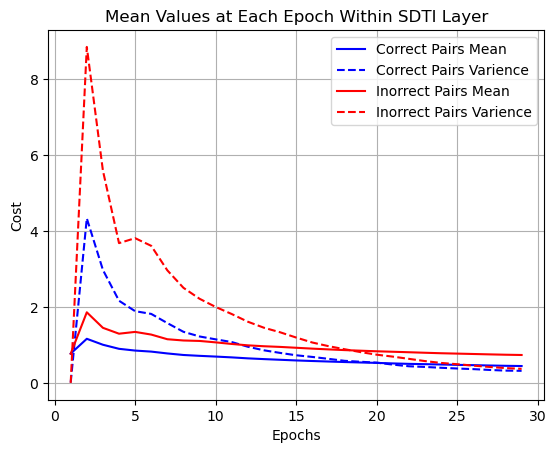

In [22]:
epochs = [i for i in range(1,30)]

plt.plot(epochs, correct_mean, label='Correct Pairs Mean', color='blue', linestyle='-')
plt.plot(epochs, correct_var, label='Correct Pairs Varience', color='blue', linestyle='--')

# plt.plot(epochs, correct_upper_bound, label='Correct Pairs +1 STD', color='blue', linestyle='--')
# plt.plot(epochs, correct_lower_bound, label='Correct Pairs -1 STD', color='blue', linestyle=':')

plt.plot(epochs, incorrect_mean, label='Inorrect Pairs Mean', color='red', linestyle='-')
plt.plot(epochs, incorrect_var, label='Inorrect Pairs Varience', color='red', linestyle='--')

# plt.plot(epochs, incorrect_upper_bound, label='Incorrect Pairs +1 STD', color='red', linestyle='--')
# plt.plot(epochs, incorrect_lower_bound, label='Incorrect Pairs -1 STD', color='red', linestyle=':')

# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Cost')
plt.title('Mean Values at Each Epoch Within SDTI Layer')

# Add a legend to distinguish the lines
plt.legend()

# Display the plot
plt.grid(True) # Optional: Add a grid for better readability
# plt.show()
plt.savefig('MeanValues.jpg')

In [15]:
correct_mean = np.mean(correct_cost_vals,axis=1)
correct_var = np.var(correct_cost_vals,axis=1)

incorrect_mean = np.mean(incorrect_cost_vals,axis=1)
incorrect_var = np.var(incorrect_cost_vals,axis=1)
print(incorrect_var.shape)

print('correct mean, var',correct_mean.mean(),correct_var.mean())

print('incorrect mean, var',incorrect_mean.mean(),incorrect_var.mean())

(163200,)
correct mean, var 0.6483490305064766 0.2597124850420332
incorrect mean, var 0.9913374363253341 0.6092657995707967


In [17]:
from scipy.stats import levene
stat, p = levene(correct_var, incorrect_var, center='mean')
# optional one-sided
print(p)
if np.var(incorrect_cost_vals) > np.var(correct_cost_vals):
    p_one_sided = p / 2
    print(p_one_sided)

1.7543183223965725e-194
8.771591611982862e-195
